# ThreFhold for SFCON 2026
This notebook is for demonstrating the ThreFhold methodology for [SFCON 2026](https://www.stat.upd.edu.ph/news/260917-2026-sfcon-registration).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from scipy.optimize import curve_fit
from sklearn.datasets import fetch_openml, make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import (
    f_classif, 
    SelectFdr, 
    SelectKBest, 
    SelectFromModel
)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score, 
    f1_score, 
    precision_score, 
    median_absolute_error, 
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm
from typing import Optional

## Introduction
The [ANOVA F-Score can be used for feature selection](https://www.geeksforgeeks.org/machine-learning/feature-selection-using-f-anova/). However, the problem with this dimensionality reduction technique is that it requires the user to select the number of features to retain. The ThreFhold methodology aims to address this problem.

The ThreFhold methodology uses the distribution of the natural logarithm of f-scores to estimate the proportion of features that are important for class determination.

## Creation of Synthetic Datasets
The creation of synthetic datasets was done using a pseudorandom number generator.

In [2]:
class DatasetGenerator:
    def __init__(self, random_state: Optional[int] = None):
        self.rng = np.random.default_rng(random_state)

    def generate_parameters(
        self,
        n_samples: Optional[int] = None,
        n_features: Optional[int] = None,
        n_classes: Optional[int] = None,
        signal_fraction: Optional[float] = None,
        n_informative: Optional[int] = None,
        class_sep: Optional[float] = None,
    ) -> dict:
        if n_samples is None:
            n_samples = int(self.rng.integers(50, 2001))
        if n_features is None:
            n_features = int(self.rng.integers(10, 501))
        if n_classes is None:
            n_classes = int(self.rng.integers(2, 11))
        if class_sep is None:
            class_sep = float(self.rng.uniform(0.5, 3.0))

        if n_informative is not None:
            n_informative = int(n_informative)
        else:
            if signal_fraction is None:
                signal_fraction = float(self.rng.uniform(0.05, 1.0))
            n_informative = max(2, round(signal_fraction * n_features))

        # sklearn geometric constraint
        n_clusters_per_class = int(self.rng.choice([1, 2]))
        min_inf = int(np.ceil(np.log2(n_classes * n_clusters_per_class)))
        if n_informative < min_inf:
            n_informative = min_inf

        # keep totals inside n_features
        n_informative = min(n_informative, n_features)

        class_weights = self.rng.dirichlet(np.ones(n_classes)).tolist()

        # realized fraction AFTER constraint fixes
        realized_fraction = n_informative / n_features

        return {
            "n_samples": n_samples,
            "n_features": n_features,
            "n_informative": n_informative,
            "n_classes": n_classes,
            "n_clusters_per_class": n_clusters_per_class,
            "weights": class_weights,
            "class_sep": class_sep,
            "random_state": int(self.rng.integers(0, 2**31 - 1)),
            "signal_fraction": realized_fraction
        }

    def generate(self, **overrides):
        params = self.generate_parameters(**overrides)

        # only keys make_classification accepts
        mc_keys = {
            "n_samples", "n_features", "n_informative",
            "n_classes", "n_clusters_per_class", "weights",
            "class_sep", "random_state",
        }
        mc_params = {k: v for k, v in params.items() if k in mc_keys}
        X, y = make_classification(
            **mc_params, 
            n_redundant = 0, 
            n_repeated = 0, 
            flip_y = 0
        )
        return X, y, params

The model for ThreFhold needed 50,000 datasets.

Unfortunately, 50,000 datasets is a lot to put into RAM, so we will preprocess the data in the same loop.

We will get the natural logarithm of the ANOVA F-scores. Then, we will get the following statistics:
- Skewness
- Shapiro-Wilk W Statistic

We will also get some desired attributes of our datasets:
- Number of Classes
- Signal Proportion (number of relevant features for classification / number of all features)

In [3]:
# # Create dataset generator object
# dataset_generator = DatasetGenerator(random_state = 42)

# dataset_count = 50_000
# datasets = []

# # Creation of datasets
# for i in tqdm(range(dataset_count)):
#     # Create dataset
#     X, y, params = dataset_generator.generate()

#     # Get natural log of F-scores
#     f_scores, _ = f_classif(X, y)
#     f_scores_log1p = np.log1p(np.nan_to_num(f_scores, nan=0.0))

#     # Get desired statistics
#     ## Number of classes
#     n_classes = params["n_classes"]

#     ## Skewness of natural log of F-scores
#     n_features = params["n_features"]
#     f_scores_log1p_skewness = np.nan
#     if n_features > 2:
#         f_scores_log1p_skewness = stats.skew(
#             f_scores_log1p,
#             bias=False
#         )

#     ## Shapiro-Wilk W Statistic of natural log of F-scores
#     f_scores_log1p_shapiro_w = np.nan
#     if n_features >= 3:
#         f_scores_log1p_shapiro_w = stats.shapiro(f_scores_log1p)[0]

#     ## Signal fraction
#     signal_fraction = params["signal_fraction"]
    
#     datasets.append({
#         "f_scores_log1p_skewness": f_scores_log1p_skewness, 
#         "n_classes": n_classes, 
#         "f_scores_log1p_shapiro_w": f_scores_log1p_shapiro_w, 
#         "signal_fraction": signal_fraction
#     })

Finally, we can put these values in a Pandas dataframe.

In [4]:
# df = pd.DataFrame(datasets)
# df = df.dropna().reset_index(drop=True)
# df.to_csv("datasets.csv", index=False)
df = pd.read_csv("datasets.csv")
df.head()

,f_scores_log1p_skewness,n_classes,f_scores_log1p_shapiro_w,signal_fraction
0,0.050416,7,0.983799,0.712821
1,0.189654,7,0.817408,0.470738
2,0.326117,8,0.990892,0.493304
3,1.294136,3,0.865313,0.265823
4,0.970660,8,0.915483,0.417178


## Exploratory Data Analysis
Now that we have our dataset of datasets, we can do our EDA.

### Finding 1: A Sigmoidal Curve made with Signal Fraction and Skewness
A model for signal fraction that uses skewness as the input can already make a decent model.

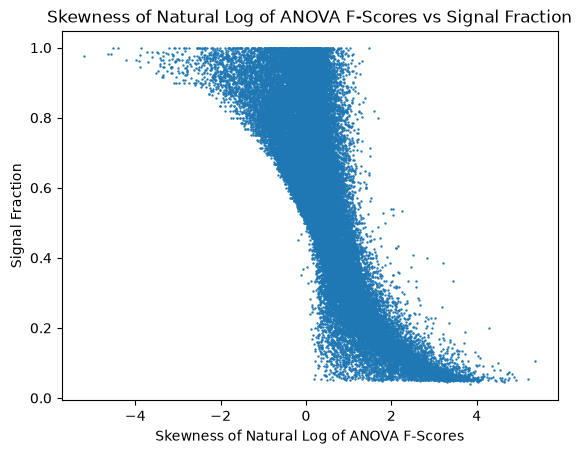

In [5]:
plt.scatter(
    df["f_scores_log1p_skewness"], 
    df["signal_fraction"], 
    s=0.5
)
plt.title("Skewness of Natural Log of ANOVA F-Scores vs Signal Fraction")
plt.xlabel("Skewness of Natural Log of ANOVA F-Scores")
plt.ylabel("Signal Fraction")
plt.show()

### Finding 2: Layered Sigmoids based on Classes
The number of classes seem to shift the sigmoid curve upwards/downwards.

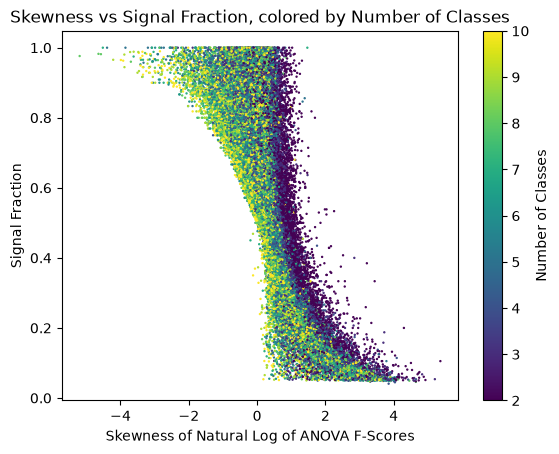

In [6]:
plt.scatter(
    df["f_scores_log1p_skewness"], 
    df["signal_fraction"], 
    c=df["n_classes"], 
    cmap='viridis', 
    s=0.5
)
plt.title("Skewness vs Signal Fraction, colored by Number of Classes")
plt.xlabel("Skewness of Natural Log of ANOVA F-Scores")
plt.ylabel("Signal Fraction")
plt.colorbar(label='Number of Classes')
plt.show()

### Finding 3: Curve Slant based on Shapiro-Wilk W Statistic
The Shapiro-Wilk W statistic seems to affect the slope of the sigmoid.

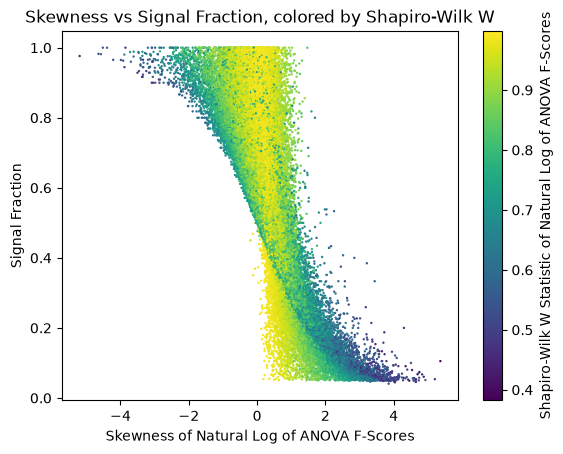

In [7]:
plt.scatter(
    df["f_scores_log1p_skewness"], 
    df["signal_fraction"], 
    c=df["f_scores_log1p_shapiro_w"], 
    cmap='viridis', 
    s=0.5
)
plt.title("Skewness vs Signal Fraction, colored by Shapiro-Wilk W")
plt.xlabel("Skewness of Natural Log of ANOVA F-Scores")
plt.ylabel("Signal Fraction")
plt.colorbar(label='Shapiro-Wilk W Statistic of Natural Log of ANOVA F-Scores')
plt.show()

## Modeling
We can now use the findings to govern the development of a model.

In [8]:
# Splitting of Data
kf = KFold(n_splits=5, shuffle=True, random_state=42)
X = df.to_numpy()[:, 0:3]
y = df.to_numpy()[:, 3]

train_sets = []
test_sets = []

for train_index, test_index in kf.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    train_sets.append({
        "X": X_train, 
        "y": y_train
    })
    test_sets.append({
        "X": X_test, 
        "y": y_test
    })

# Function for calculating performances
def eval_performance(y, y_pred):
    """
    Evaluates performances of the models
    """
    r2 = r2_score(y, y_pred)
    mse = mean_squared_error(y, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y, y_pred)
    medae = median_absolute_error(y, y_pred)
    std_err = np.std(y - y_pred, ddof=1)

    return {
        "R^2": r2, 
        "Mean Squared Error": mse, 
        "Root Mean Squared Error": rmse, 
        "Mean Absolute Error": mae, 
        "Median Absolute Error": medae, 
        "Error Standard Deviation": std_err
    }

# Function for CV
def cross_validate(f):
    train_perfs = []
    test_perfs  = []
    
    for i in range(len(train_sets)):
        # Train model
        popt, _ = curve_fit(
            f, 
            train_sets[i]["X"], 
            train_sets[i]["y"], 
            maxfev=10_000
        )

        # Get predictions
        y_pred_train = f(train_sets[i]["X"], *popt)
        y_pred_test  = f(test_sets[i]["X"], *popt)

        train_perf_i = eval_performance(train_sets[i]["y"], y_pred_train)
        test_perf_i  = eval_performance(test_sets[i]["y"], y_pred_test)

        train_perfs.append(train_perf_i)
        test_perfs.append(test_perf_i)

    train_perf_mean = pd.DataFrame(train_perfs).mean().rename("Train")
    test_perf_mean = pd.DataFrame(test_perfs).mean().rename("Test")

    return pd.concat([ train_perf_mean, test_perf_mean ], axis = "columns").T

### Model 1: Simple Skewness Model

In [9]:
def logistic_decay(x, L, k, x0, b):
    return L / (1 + np.exp(k * (x[:, 0] - x0))) + b

cross_validate(logistic_decay)

,R^2,Mean Squared Error,Root Mean Squared Error,Mean Absolute Error,Median Absolute Error,Error Standard Deviation
Train,0.740779,0.019401,0.139287,0.104926,0.083917,0.139289
Test,0.740683,0.019405,0.139294,0.104941,0.083865,0.139285


### Model 2: Skewness Model with Log of N Classes as Offset

In [10]:
def x0_n_classes_log(x, L, k, x0, b, p, q):
    skewness = x[:, 0]
    n_classes = x[:, 1]

    x0_n_classes = p * np.log(
        np.maximum(n_classes + q, 1e-8)
    )
    return L / (1 + np.exp(k * (skewness - x0_n_classes - x0))) + b

cross_validate(x0_n_classes_log)

,R^2,Mean Squared Error,Root Mean Squared Error,Mean Absolute Error,Median Absolute Error,Error Standard Deviation
Train,0.790579,0.015673,0.125162,0.092851,0.067811,0.125163
Test,0.790759,0.015661,0.125089,0.092835,0.068115,0.125083


### Model 3: Skewness Model with Slant affected by Shapiro-Wilk W Statistic

In [11]:
def k_shapiro_w_rational(
    x, L, k, x0, b, 
    p1, p0, q1, q0
):
    skewness = x[:, 0]
    shapiro_w = x[:, 2]

    k_shapiro_w = (p1 * shapiro_w + p0) / (q1 * shapiro_w + q0)
    return L / (1 + np.exp((k - k_shapiro_w) * (skewness - x0))) + b

cross_validate(k_shapiro_w_rational)

/var/folders/cn/w9246zrd5kd2ns6x7dyz682m0000gn/T/ipykernel_7271/4086926484.py:9: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp((k - k_shapiro_w) * (skewness - x0))) + b
/var/folders/cn/w9246zrd5kd2ns6x7dyz682m0000gn/T/ipykernel_7271/4086926484.py:9: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp((k - k_shapiro_w) * (skewness - x0))) + b
/var/folders/cn/w9246zrd5kd2ns6x7dyz682m0000gn/T/ipykernel_7271/4086926484.py:9: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp((k - k_shapiro_w) * (skewness - x0))) + b
/var/folders/cn/w9246zrd5kd2ns6x7dyz682m0000gn/T/ipykernel_7271/4086926484.py:9: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp((k - k_shapiro_w) * (skewness - x0))) + b
/var/folders/cn/w9246zrd5kd2ns6x7dyz682m0000gn/T/ipykernel_7271/4086926484.py:9: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp((k - k_shapiro_w) * (skewness - x0))) + b


,R^2,Mean Squared Error,Root Mean Squared Error,Mean Absolute Error,Median Absolute Error,Error Standard Deviation
Train,0.778210,0.016600,0.128839,0.092214,0.067454,0.128840
Test,0.778104,0.016605,0.128846,0.092230,0.067476,0.128842


### Combined Model

In [12]:
# Function for CV
def combined_cross_validate(f1, f2, f3):
    train_perfs = []
    test_perfs  = []
    
    for i in range(len(train_sets)):
        # Train models
        popt1, _ = curve_fit(
            f1, 
            train_sets[i]["X"], 
            train_sets[i]["y"], 
            maxfev=10_000
        )
        popt2, _ = curve_fit(
            f2, 
            train_sets[i]["X"], 
            train_sets[i]["y"], 
            maxfev=10_000
        )
        popt3, _ = curve_fit(
            f3, 
            train_sets[i]["X"], 
            train_sets[i]["y"], 
            maxfev=10_000
        )

        # Get predictions of individual models
        y_indiv_pred_train1 = f1(train_sets[i]["X"], *popt1)
        y_indiv_pred_train2 = f2(train_sets[i]["X"], *popt2)
        y_indiv_pred_train3 = f3(train_sets[i]["X"], *popt3)
        y_indiv_pred_test1 = f1(test_sets[i]["X"], *popt1)
        y_indiv_pred_test2 = f2(test_sets[i]["X"], *popt2)
        y_indiv_pred_test3 = f3(test_sets[i]["X"], *popt3)

        # Combine individual predictions
        y_indiv_pred_train = np.array(
            [
                y_indiv_pred_train1, 
                y_indiv_pred_train2, 
                y_indiv_pred_train3
            ]
        ).T
        y_indiv_pred_test = np.array(
            [
                y_indiv_pred_test1, 
                y_indiv_pred_test2, 
                y_indiv_pred_test3
            ]
        ).T

        # Create linear regression model
        reg = LinearRegression().fit(y_indiv_pred_train, train_sets[i]["y"])
        
        # Evaluate model
        y_pred_train = reg.predict(y_indiv_pred_train)
        y_pred_test  = reg.predict(y_indiv_pred_test)

        train_perf_i = eval_performance(train_sets[i]["y"], y_pred_train)
        test_perf_i  = eval_performance(test_sets[i]["y"], y_pred_test)

        train_perfs.append(train_perf_i)
        test_perfs.append(test_perf_i)

    train_perf_mean = pd.DataFrame(train_perfs).mean().rename("Train")
    test_perf_mean = pd.DataFrame(test_perfs).mean().rename("Test")

    return pd.concat([ train_perf_mean, test_perf_mean ], axis = "columns").T

In [13]:
combined_cross_validate(
    logistic_decay, 
    x0_n_classes_log, 
    k_shapiro_w_rational
)

/var/folders/cn/w9246zrd5kd2ns6x7dyz682m0000gn/T/ipykernel_7271/4086926484.py:9: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp((k - k_shapiro_w) * (skewness - x0))) + b
/var/folders/cn/w9246zrd5kd2ns6x7dyz682m0000gn/T/ipykernel_7271/4086926484.py:9: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp((k - k_shapiro_w) * (skewness - x0))) + b
/var/folders/cn/w9246zrd5kd2ns6x7dyz682m0000gn/T/ipykernel_7271/4086926484.py:9: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp((k - k_shapiro_w) * (skewness - x0))) + b
/var/folders/cn/w9246zrd5kd2ns6x7dyz682m0000gn/T/ipykernel_7271/4086926484.py:9: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp((k - k_shapiro_w) * (skewness - x0))) + b
/var/folders/cn/w9246zrd5kd2ns6x7dyz682m0000gn/T/ipykernel_7271/4086926484.py:9: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp((k - k_shapiro_w) * (skewness - x0))) + b


,R^2,Mean Squared Error,Root Mean Squared Error,Mean Absolute Error,Median Absolute Error,Error Standard Deviation
Train,0.845046,0.011597,0.107634,0.073748,0.048719,0.107635
Test,0.845198,0.011588,0.107532,0.073741,0.048739,0.107532


### Final Class for Calculating ThreFhold

In [14]:
class ThreFhold:
    def __init__(self):
        # Define models
        self.f1 = logistic_decay
        self.f2 = x0_n_classes_log
        self.f3 = k_shapiro_w_rational
        
        # Train models
        self.popt1, _ = curve_fit(
            self.f1, X, y, 
            maxfev=10_000
        )
        self.popt2, _ = curve_fit(
            self.f2, X, y, 
            maxfev=10_000
        )
        self.popt3, _ = curve_fit(
            self.f3, X, y, 
            maxfev=10_000
        )
        
        # Ensemble
        y_indiv_pred1 = self.f1(X, *self.popt1)
        y_indiv_pred2 = self.f2(X, *self.popt2)
        y_indiv_pred3 = self.f3(X, *self.popt3)
        y_indiv_pred = np.array(
            [
                y_indiv_pred1, 
                y_indiv_pred2, 
                y_indiv_pred3
            ]
        ).T
        
        # Create linear regression model
        self.reg = LinearRegression().fit(y_indiv_pred, y)

    def predict(self, data_X, data_y):
        # Standard scale data
        data_X_scaled = StandardScaler().fit_transform(data_X)

        # Get needed model inputs
        ## Natural log of F-scores
        f_scores, _ = f_classif(data_X_scaled, data_y)
        f_scores_log1p = np.log1p(np.nan_to_num(f_scores, nan=0.0))

        ## Number of classes
        n_classes = len(set(data_y))
    
        ## Skewness of natural log of F-scores
        n_features = data_X.shape[1]
        f_scores_log1p_skewness = np.nan
        if n_features > 2:
            f_scores_log1p_skewness = stats.skew(
                f_scores_log1p,
                bias=False
            )
    
        ## Shapiro-Wilk W Statistic of natural log of F-scores
        f_scores_log1p_shapiro_w = np.nan
        if n_features >= 3:
            f_scores_log1p_shapiro_w = stats.shapiro(f_scores_log1p)[0]

        # Aggregate model inputs
        y_indiv_x = np.array([[
            f_scores_log1p_skewness, 
            n_classes, 
            f_scores_log1p_shapiro_w
        ]])

        # Run model
        y_indiv_pred1 = self.f1(y_indiv_x, *self.popt1)
        y_indiv_pred2 = self.f2(y_indiv_x, *self.popt2)
        y_indiv_pred3 = self.f3(y_indiv_x, *self.popt3)

        y_indiv_pred = np.array([
            y_indiv_pred1, y_indiv_pred2, y_indiv_pred3
        ]).T

        prediction = self.reg.predict(y_indiv_pred)[0]
        
        # Clip prediction
        if prediction > 1:
            prediction = 1
        elif prediction < 0:
            prediction = 1e-6
        
        return prediction

## Evaluating ThreFhold

In [15]:
def eval_classification_performance(y, y_pred):
    return {
        "Accuracy": accuracy_score(y, y_pred),
        "F1 Score": f1_score(y, y_pred, average="macro"),
        "Precision": precision_score(y, y_pred, average="macro"),
    }

In [16]:
threfhold = ThreFhold()

/var/folders/cn/w9246zrd5kd2ns6x7dyz682m0000gn/T/ipykernel_7271/4086926484.py:9: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp((k - k_shapiro_w) * (skewness - x0))) + b


### Human Activity Recognition

In [17]:
# Load the HAR dataset
X_har, y_har = fetch_openml(
    'har', version=1, return_X_y=True, parser='auto'
)

# Split data
X_train_har, X_test_har, y_train_har, y_test_har = train_test_split(
    X_har, y_har, 
    test_size=0.3, 
    random_state=42
)

#### ThreFhold

In [18]:
# Compute k
signal_proportion_har = threfhold.predict(X_train_har.to_numpy(), y_train_har)
k_har = np.ceil(X_har.shape[1] * signal_proportion_har).astype(int)

print(f"Number of Features Selected for HAR Dataset: {k_har}")

# Evaluate
selector_har = SelectKBest(score_func=f_classif, k=k_har)
X_train_selected_har = selector_har.fit_transform(
    X_train_har, y_train_har
)
X_test_selected_har = selector_har.transform(X_test_har)

# Fit model
model_har = RandomForestClassifier(random_state=42)
model_har.fit(X_train_selected_har, y_train_har)

# Evaluate
y_pred_train_har = model_har.predict(X_train_selected_har)
y_pred_test_har  = model_har.predict(X_test_selected_har)
train_perf_har = eval_classification_performance(
    y_train_har, y_pred_train_har
)
test_perf_har  = eval_classification_performance(
    y_test_har, y_pred_test_har
)

pd.DataFrame(
    [train_perf_har, test_perf_har], 
    index=["Train", "Test"]
)

Number of Features Selected for HAR Dataset: 523


,Accuracy,F1 Score,Precision
Train,1.000000,1.000000,1.000000
Test,0.976052,0.976273,0.976154


#### Benjamini-Hochberg Procedure

In [19]:
# Evaluate
selector_har = SelectFdr()
X_train_selected_har = selector_har.fit_transform(
    X_train_har, y_train_har
)
X_test_selected_har = selector_har.transform(X_test_har)

print(f"Number of features selected by FDR for HAR Dataset: {X_test_selected_har.shape[1]}")

# Fit model
model_har = RandomForestClassifier(random_state=42)
model_har.fit(X_train_selected_har, y_train_har)

# Evaluate
y_pred_train_har = model_har.predict(X_train_selected_har)
y_pred_test_har  = model_har.predict(X_test_selected_har)
train_perf_har = eval_classification_performance(
    y_train_har, y_pred_train_har
)
test_perf_har  = eval_classification_performance(
    y_test_har, y_pred_test_har
)

pd.DataFrame(
    [train_perf_har, test_perf_har], 
    index=["Train", "Test"]
)

Number of features selected by FDR for HAR Dataset: 555


,Accuracy,F1 Score,Precision
Train,1.000000,1.00000,1.000000
Test,0.977023,0.97717,0.977063


#### L2 Regularization

In [20]:
har_scaler = StandardScaler().fit(X_train_har)

# Evaluate
selector_har = SelectFromModel(
    LogisticRegression(
        random_state=42, 
        max_iter=20_000
    )
)
X_train_selected_har = selector_har.fit_transform(
    har_scaler.transform(X_train_har), y_train_har
)
X_test_selected_har = selector_har.transform(har_scaler.transform(X_test_har))

print(f"Number of features selected by L2 Regularization for HAR Dataset: {X_test_selected_har.shape[1]}")

# Fit model
model_har = RandomForestClassifier(random_state=42)
model_har.fit(X_train_selected_har, y_train_har)

# Evaluate
y_pred_train_har = model_har.predict(X_train_selected_har)
y_pred_test_har  = model_har.predict(X_test_selected_har)
train_perf_har = eval_classification_performance(
    y_train_har, y_pred_train_har
)
test_perf_har  = eval_classification_performance(
    y_test_har, y_pred_test_har
)

pd.DataFrame(
    [train_perf_har, test_perf_har], 
    index=["Train", "Test"]
)

Number of features selected by L2 Regularization for HAR Dataset: 191


,Accuracy,F1 Score,Precision
Train,1.00000,1.000000,1.000000
Test,0.97411,0.974363,0.974475


#### L1 Regularization

In [21]:
har_scaler = StandardScaler().fit(X_train_har)

# Evaluate
selector_har = SelectFromModel(
    LogisticRegression(
        random_state=42, 
        max_iter=20_000, 
        l1_ratio=1.0, 
        solver="saga"
    )
)
X_train_selected_har = selector_har.fit_transform(
    har_scaler.transform(X_train_har), y_train_har
)
X_test_selected_har = selector_har.transform(har_scaler.transform(X_test_har))

print(f"Number of features selected by L1 Regularization for HAR Dataset: {X_test_selected_har.shape[1]}")

# Fit model
model_har = RandomForestClassifier(random_state=42)
model_har.fit(X_train_selected_har, y_train_har)

# Evaluate
y_pred_train_har = model_har.predict(X_train_selected_har)
y_pred_test_har  = model_har.predict(X_test_selected_har)
train_perf_har = eval_classification_performance(
    y_train_har, y_pred_train_har
)
test_perf_har  = eval_classification_performance(
    y_test_har, y_pred_test_har
)

pd.DataFrame(
    [train_perf_har, test_perf_har], 
    index=["Train", "Test"]
)

Number of features selected by L1 Regularization for HAR Dataset: 425


,Accuracy,F1 Score,Precision
Train,1.000000,1.000000,1.000000
Test,0.975081,0.975026,0.974963


### Gisette

In [22]:
# Load the Gisette dataset
X_gisette, y_gisette = fetch_openml(
    'gisette', version=2, return_X_y=True, parser='auto'
)

# Split data
X_train_gisette, X_test_gisette, y_train_gisette, y_test_gisette = (
    train_test_split(X_gisette, y_gisette, test_size=0.3, random_state=42)
)

#### ThreFhold

In [23]:
# Compute k
signal_proportion_gisette = threfhold.predict(
    X_train_gisette.toarray(), y_train_gisette
)
k_gisette = np.ceil(
    X_train_gisette.shape[1] * signal_proportion_gisette
).astype(int)

print(f"Number of Features Selected for Gisette Dataset: {k_gisette}")

# Evaluate
selector_gisette = SelectKBest(score_func=f_classif, k=k_gisette)
X_train_selected_gisette = selector_gisette.fit_transform(
    X_train_gisette, y_train_gisette
)
X_test_selected_gisette = selector_gisette.transform(X_test_gisette)

# Fit model
model_gisette = RandomForestClassifier(random_state=42)
model_gisette.fit(X_train_selected_gisette, y_train_gisette)

# Evaluate
y_pred_train_gisette = model_gisette.predict(X_train_selected_gisette)
y_pred_test_gisette = model_gisette.predict(X_test_selected_gisette)
train_perf_gisette = eval_classification_performance(
    y_train_gisette, y_pred_train_gisette
)
test_perf_gisette = eval_classification_performance(
    y_test_gisette, y_pred_test_gisette
)

pd.DataFrame(
    [train_perf_gisette, test_perf_gisette], 
    index=["Train", "Test"]
)

/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [  18   21  119  157  175  421  475  479  539  625  793  876 1004 1076
 1102 1167 1639 1676 1681 1792 1825 1835 2022 2055 2070 2198 2248 2348
 2371 2585 2604 2686 2703 2718 2737 2785 2811 2901 2939 3007 3026 3193
 3476 3505 3536 3556 3629 3631 3706 3864 4066 4100 4236 4255 4396 4462
 4521 4634 4650 4964] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0] are constant.
  warnings.warn("Features %s are constant." % con

Number of Features Selected for Gisette Dataset: 2726


,Accuracy,F1 Score,Precision
Train,1.00,1.000000,1.000000
Test,0.97,0.969999,0.970047


#### Benjamini-Hochberg Procedure

In [24]:
# Evaluate
selector_gisette = SelectFdr()
X_train_selected_gisette = selector_gisette.fit_transform(
    X_train_gisette.toarray(), y_train_gisette
)
X_test_selected_gisette = selector_gisette.transform(X_test_gisette)

print(f"Number of features selected by FDR for Gisette Dataset: {X_test_selected_gisette.shape[1]}")

# Fit model
model_gisette = RandomForestClassifier(random_state=42)
model_gisette.fit(X_train_selected_gisette, y_train_gisette)

# Evaluate
y_pred_train_gisette = model_gisette.predict(X_train_selected_gisette)
y_pred_test_gisette  = model_gisette.predict(X_test_selected_gisette)
train_perf_gisette = eval_classification_performance(
    y_train_gisette, y_pred_train_gisette
)
test_perf_gisette  = eval_classification_performance(
    y_test_gisette, y_pred_test_gisette
)

pd.DataFrame(
    [train_perf_gisette, test_perf_gisette], 
    index=["Train", "Test"]
)

/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [  18   21  119  157  175  421  475  479  539  625  793  876 1004 1076
 1102 1167 1639 1676 1681 1792 1825 1835 2022 2055 2070 2198 2248 2348
 2371 2585 2604 2686 2703 2718 2737 2785 2811 2901 2939 3007 3026 3193
 3476 3505 3536 3556 3629 3631 3706 3864 4066 4100 4236 4255 4396 4462
 4521 4634 4650 4964] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


Number of features selected by FDR for Gisette Dataset: 1843


,Accuracy,F1 Score,Precision
Train,1.000000,1.000000,1.000000
Test,0.970952,0.970952,0.971024


#### L2 Regularization

In [25]:
gisette_scaler = StandardScaler().fit(X_train_gisette.toarray())

# Evaluate
selector_gisette = SelectFromModel(
    LogisticRegression(
        random_state=42, 
        max_iter=20_000
    )
)
X_train_selected_gisette = selector_gisette.fit_transform(
    gisette_scaler.transform(X_train_gisette.toarray()), y_train_gisette
)
X_test_selected_gisette = selector_gisette.transform(gisette_scaler.transform(X_test_gisette.toarray()))

print(f"Number of features selected by L2 Regularization for Gisette Dataset: {X_train_selected_gisette.shape[1]}")

# Fit model
model_gisette = RandomForestClassifier(random_state=42)
model_gisette.fit(X_train_selected_gisette, y_train_gisette)

# Evaluate
y_pred_train_gisette = model_gisette.predict(X_train_selected_gisette)
y_pred_test_gisette  = model_gisette.predict(X_test_selected_gisette)
train_perf_gisette = eval_classification_performance(
    y_train_gisette, y_pred_train_gisette
)
test_perf_gisette  = eval_classification_performance(
    y_test_gisette, y_pred_test_gisette
)

pd.DataFrame(
    [train_perf_gisette, test_perf_gisette], 
    index=["Train", "Test"]
)

Number of features selected by L2 Regularization for Gisette Dataset: 1954


,Accuracy,F1 Score,Precision
Train,1.000000,1.000000,1.000000
Test,0.965238,0.965236,0.965246


#### L1 Regularization

In [26]:
gisette_scaler = StandardScaler().fit(X_train_gisette.toarray())

# Evaluate
selector_gisette = SelectFromModel(
    LogisticRegression(
        random_state=42, 
        max_iter=20_000, 
        l1_ratio=1.0, 
        solver="saga"
    )
)
X_train_selected_gisette = selector_gisette.fit_transform(
    gisette_scaler.transform(X_train_gisette.toarray()), y_train_gisette
)
X_test_selected_gisette = selector_gisette.transform(gisette_scaler.transform(X_test_gisette.toarray()))

print(f"Number of features selected by L1 Regularization for Gisette Dataset: {X_train_selected_gisette.shape[1]}")

# Fit model
model_gisette = RandomForestClassifier(random_state=42)
model_gisette.fit(X_train_selected_gisette, y_train_gisette)

# Evaluate
y_pred_train_gisette = model_gisette.predict(X_train_selected_gisette)
y_pred_test_gisette  = model_gisette.predict(X_test_selected_gisette)
train_perf_gisette = eval_classification_performance(
    y_train_gisette, y_pred_train_gisette
)
test_perf_gisette  = eval_classification_performance(
    y_test_gisette, y_pred_test_gisette
)

pd.DataFrame(
    [train_perf_gisette, test_perf_gisette], 
    index=["Train", "Test"]
)

Number of features selected by L1 Regularization for Gisette Dataset: 1399


,Accuracy,F1 Score,Precision
Train,1.000000,1.00000,1.000000
Test,0.969524,0.96952,0.969496


### Madelon

In [27]:
# Load the Madelon dataset
X_madelon, y_madelon = fetch_openml(
    'madelon', version=1, return_X_y=True, parser='auto'
)

# Split data
X_train_madelon, X_test_madelon, y_train_madelon, y_test_madelon = train_test_split(
    X_madelon, y_madelon, 
    test_size=0.3, 
    random_state=42
)

#### ThreFhold

In [28]:
# Compute k
signal_proportion_madelon = threfhold.predict(X_train_madelon.to_numpy(), y_train_madelon)
k_madelon = np.ceil(X_madelon.shape[1] * signal_proportion_madelon).astype(int)

print(f"Number of Features Selected for Madelon Dataset: {k_madelon}")

# Evaluate
selector_madelon = SelectKBest(score_func=f_classif, k=k_madelon)
X_train_selected_madelon = selector_madelon.fit_transform(
    X_train_madelon, y_train_madelon
)
X_test_selected_madelon = selector_madelon.transform(X_test_madelon)

# Fit model
model_madelon = RandomForestClassifier(random_state=42)
model_madelon.fit(X_train_selected_madelon, y_train_madelon)

# Evaluate
y_pred_train_madelon = model_madelon.predict(X_train_selected_madelon)
y_pred_test_madelon  = model_madelon.predict(X_test_selected_madelon)
train_perf_madelon = eval_classification_performance(
    y_train_madelon, y_pred_train_madelon
)
test_perf_madelon  = eval_classification_performance(
    y_test_madelon, y_pred_test_madelon
)

pd.DataFrame(
    [train_perf_madelon, test_perf_madelon], 
    index=["Train", "Test"]
)

Number of Features Selected for Madelon Dataset: 81


,Accuracy,F1 Score,Precision
Train,1.000000,1.000000,1.000000
Test,0.742308,0.741662,0.743399


#### Benjamini-Hochberg Procedure

In [29]:
# Evaluate
selector_madelon = SelectFdr()
X_train_selected_madelon = selector_madelon.fit_transform(
    X_train_madelon, y_train_madelon
)
X_test_selected_madelon = selector_madelon.transform(X_test_madelon)

print(f"Number of features selected by FDR for Madelon Dataset: {X_test_selected_madelon.shape[1]}")

# Fit model
model_madelon = RandomForestClassifier(random_state=42)
model_madelon.fit(X_train_selected_madelon, y_train_madelon)

# Evaluate
y_pred_train_madelon = model_madelon.predict(X_train_selected_madelon)
y_pred_test_madelon  = model_madelon.predict(X_test_selected_madelon)
train_perf_madelon = eval_classification_performance(
    y_train_madelon, y_pred_train_madelon
)
test_perf_madelon  = eval_classification_performance(
    y_test_madelon, y_pred_test_madelon
)

pd.DataFrame(
    [train_perf_madelon, test_perf_madelon], 
    index=["Train", "Test"]
)

Number of features selected by FDR for Madelon Dataset: 14


,Accuracy,F1 Score,Precision
Train,1.000000,1.000000,1.000000
Test,0.862821,0.862739,0.862967


#### L2 Regularization

In [30]:
madelon_scaler = StandardScaler().fit(X_train_madelon)

# Evaluate
selector_madelon = SelectFromModel(
    LogisticRegression(
        random_state=42, 
        max_iter=20_000
    )
)
X_train_selected_madelon = selector_madelon.fit_transform(
    madelon_scaler.transform(X_train_madelon), y_train_madelon
)
X_test_selected_madelon = selector_madelon.transform(madelon_scaler.transform(X_test_madelon))

print(f"Number of features selected by L2 Regularization for Madelon Dataset: {X_test_selected_madelon.shape[1]}")

# Fit model
model_madelon = RandomForestClassifier(random_state=42)
model_madelon.fit(X_train_selected_madelon, y_train_madelon)

# Evaluate
y_pred_train_madelon = model_madelon.predict(X_train_selected_madelon)
y_pred_test_madelon  = model_madelon.predict(X_test_selected_madelon)
train_perf_madelon = eval_classification_performance(
    y_train_madelon, y_pred_train_madelon
)
test_perf_madelon  = eval_classification_performance(
    y_test_madelon, y_pred_test_madelon
)

pd.DataFrame(
    [train_perf_madelon, test_perf_madelon], 
    index=["Train", "Test"]
)

Number of features selected by L2 Regularization for Madelon Dataset: 190


,Accuracy,F1 Score,Precision
Train,1.000000,1.000000,1.000000
Test,0.739744,0.739023,0.740994


#### L1 Regularization

In [31]:
madelon_scaler = StandardScaler().fit(X_train_madelon)

# Evaluate
selector_madelon = SelectFromModel(
    LogisticRegression(
        random_state=42, 
        max_iter=20_000, 
        l1_ratio=1.0, 
        solver="saga"
    )
)
X_train_selected_madelon = selector_madelon.fit_transform(
    madelon_scaler.transform(X_train_madelon), y_train_madelon
)
X_test_selected_madelon = selector_madelon.transform(madelon_scaler.transform(X_test_madelon))

print(f"Number of features selected by L1 Regularization for Madelon Dataset: {X_test_selected_madelon.shape[1]}")

# Get selected columns
selected_features_madelon = X_madelon.columns[selector_madelon.get_support()]

# Fit model
model_madelon = RandomForestClassifier(random_state=42)
model_madelon.fit(X_train_selected_madelon, y_train_madelon)

# Evaluate
y_pred_train_madelon = model_madelon.predict(X_train_selected_madelon)
y_pred_test_madelon  = model_madelon.predict(X_test_selected_madelon)
train_perf_madelon = eval_classification_performance(
    y_train_madelon, y_pred_train_madelon
)
test_perf_madelon  = eval_classification_performance(
    y_test_madelon, y_pred_test_madelon
)

pd.DataFrame(
    [train_perf_madelon, test_perf_madelon], 
    index=["Train", "Test"]
)

Number of features selected by L1 Regularization for Madelon Dataset: 480


,Accuracy,F1 Score,Precision
Train,1.000000,1.000000,1.000000
Test,0.646154,0.646154,0.646307
